# code_028 · Learning structure without target labels

**Book:** section 6.2. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_06_GUIDE.md), [execution evidence](../CHAPTER_06_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_028). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=628;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 628


<a id="objectives"></a>
## No inspection targets enter these fits

Generate 720 independent sensor snapshots from three operating regimes. Regime means in three channels are (-2,0,1),(0,2,-1),(2,-1,0), with Gaussian sensor noise sd .35 in arbitrary fixed reference units. A separate binary finding is drawn independently with probability .35. Regime and finding labels are kept out of every unsupervised fit. Their later comparison checks interpretation rather than selecting settings. Roles: 480 training/120 development/120 final snapshots.

Fixed training-only StandardScaler; KMeans(n_clusters=3,n_init=10,random_state=SEED); GaussianMixture(n_components=3,covariance_type='full',reg_covar=1e-4,max_iter=300,random_state=SEED). K-means minimizes squared distances, GMM fits a probability density in standardized coordinates, and the autoencoder below minimizes reconstruction error. Three components are declared for this toy, not inferred as a true damage count.


Training inertia: 137.9490027861646 development mean log density: -1.4905137797457442


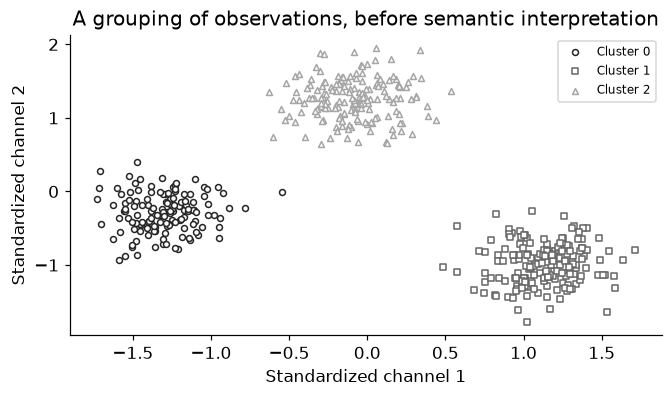

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
N=720;regime=rng.integers(0,3,N);means=np.array([[-2.,0.,1.],[0.,2.,-1.],[2.,-1.,0.]])
raw=means[regime]+rng.normal(0,.35,(N,3));finding=rng.binomial(1,.35,N)
tr=np.arange(480);dv=np.arange(480,600);te=np.arange(600,720)
scaler=StandardScaler().fit(raw[tr]);X=scaler.transform(raw)
cluster=KMeans(n_clusters=3,n_init=10,random_state=SEED).fit(X[tr])
density=GaussianMixture(n_components=3,covariance_type='full',reg_covar=1e-4,max_iter=300,random_state=SEED).fit(X[tr])
assert not set(tr)&set(dv) and not set(tr)&set(te) and not set(dv)&set(te)
assert np.allclose(scaler.mean_,raw[tr].mean(0)) and density.converged_
assert cluster.cluster_centers_.shape==(3,3) and density.weights_.shape==(3,)
print('Training inertia:',cluster.inertia_,'development mean log density:',density.score(X[dv]))
fig,ax=plt.subplots(figsize=(6,3.5))
for k,marker in enumerate(['o','s','^']):
 selected=cluster.labels_==k;ax.scatter(X[tr][selected,0],X[tr][selected,1],s=15,marker=marker,facecolors='white',edgecolors=str(.15+.25*k),label=f'Cluster {k}')
ax.set(xlabel='Standardized channel 1',ylabel='Standardized channel 2',title='A grouping of observations, before semantic interpretation');ax.legend(fontsize=8);plt.show()


<a id="autoencoder"></a>
## Train a real bottleneck autoencoder

Encoder h=tanh(X@W+b) has two units; decoder h@V+c has three outputs. Optimize half mean squared Euclidean reconstruction error by full-batch gradients for 1200 fixed steps at rate .03. Initial weights use sd .15; biases start at zero. No labels, development or final cases set these parameters. Check a decoder derivative against finite differences before updates. This is actual nonlinear representation fitting, not a relabelled PCA calculation. Reconstruction encourages retained information but does not guarantee finding-relevant features.


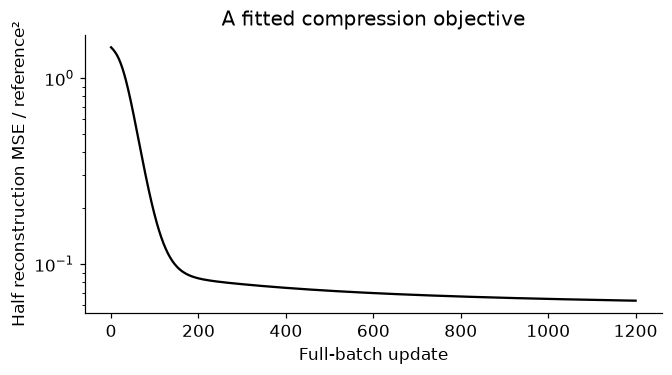

In [3]:
W=rng.normal(0,.15,(3,2));b=np.zeros(2);V=rng.normal(0,.15,(2,3));c=np.zeros(3)
def forward(Z):
 h=np.tanh(Z@W+b);return h,h@V+c
def objective(Z):return .5*np.mean(np.sum((forward(Z)[1]-Z)**2,axis=1))
h,pred=forward(X[tr]);residual=(pred-X[tr])/len(tr);gradV=h.T@residual
old=V[0,0];delta=1e-6;V[0,0]=old+delta;plus=objective(X[tr]);V[0,0]=old-delta;minus=objective(X[tr]);V[0,0]=old
assert np.isclose((plus-minus)/(2*delta),gradV[0,0],rtol=1e-5,atol=1e-7)
history=[objective(X[tr])]
for step in range(1200):
 h,pred=forward(X[tr]);r=(pred-X[tr])/len(tr);dV=h.T@r;dc=r.sum(0);dh=(r@V.T)*(1-h*h);dW=X[tr].T@dh;db=dh.sum(0)
 W-=.03*dW;b-=.03*db;V-=.03*dV;c-=.03*dc
 history.append(objective(X[tr]))
assert history[-1]<history[0] and np.isfinite(history).all()
assert forward(X[dv])[0].shape==(120,2)
fig,ax=plt.subplots(figsize=(6,3.3));ax.semilogy(history,'k-');ax.set(xlabel='Full-batch update',ylabel='Half reconstruction MSE / reference²',title='A fitted compression objective');plt.show()
RESULTS['training_reconstruction_initial_final']=list(map(float,[history[0],history[-1]]))


<a id="interpretation"></a>
## Freeze the fits, then evaluate distinct claims

Final regime labels check whether clusters recover the constructed operating regimes; independent finding labels check a different proposed meaning. Adjusted Rand index is invariant to the arbitrary cluster-number permutation. It is an external descriptive agreement score here, not a label used to fit or select clusters. Final reconstruction is compared with the training-mean zero-vector reconstruction baseline in standardized coordinates. A separately constructed far-out sensor vector tests the density's ranking, not a calibrated anomaly threshold. Density units change under rescaling; low density alone does not define a dangerous case.


In [4]:
labels=cluster.predict(X[te]);ari_regime=float(adjusted_rand_score(regime[te],labels));ari_finding=float(adjusted_rand_score(finding[te],labels))
reconstruction=float(objective(X[te]));baseline=float(.5*np.mean(np.sum(X[te]**2,axis=1)))
normal_log_density=float(density.score(X[te]));far_log_density=float(density.score(np.full((1,3),8.)))
assert np.isfinite([ari_regime,ari_finding,reconstruction,baseline,normal_log_density,far_log_density]).all()
assert far_log_density<normal_log_density and reconstruction<baseline
assert np.array_equal(np.sort(np.unique(labels)),np.array([0,1,2]))
RESULTS.update({'final_regime_ARI':ari_regime,'final_finding_ARI':ari_finding,'final_half_reconstruction_MSE':reconstruction,'mean_baseline_half_MSE':baseline,'final_mean_log_density':normal_log_density,'far_query_log_density':far_log_density});print(RESULTS)


{'training_reconstruction_initial_final': [1.4631012907940226, 0.06352197791931974], 'final_regime_ARI': 1.0, 'final_finding_ARI': -0.0050318003708739924, 'final_half_reconstruction_MSE': 0.05888968402887595, 'mean_baseline_half_MSE': 1.5566686529077935, 'final_mean_log_density': -1.6075697099218778, 'far_query_log_density': -1166.3166393389438}


<a id="exercises"></a>
## Exercises and hints

1. Increase a nuisance temperature variation and inspect whether clusters follow it. Define usefulness using independent outcomes before selecting settings.
2. Compare bottleneck sizes one and three on development data; explain the identity-copying shortcut of an unrestricted reconstruction model.
3. Change sensor units and track the density Jacobian. Keep density scores in comparable coordinates.
4. Inject rare but benign regimes and common dangerous cases. Explain why rarity, reconstruction error and consequence differ.

**Hints:** cluster indices have no intrinsic semantic order. Reconstruction and likelihood are objectives, not externally supplied damage meanings. A useful discovered representation needs an independent downstream test. See official [clustering](https://scikit-learn.org/1.9/modules/clustering.html) and [Gaussian mixtures](https://scikit-learn.org/1.9/modules/mixture.html) documentation. Check scaling, convergence and sampling units before interpreting groups.


In [5]:
summary={'example_id':'code_028','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['clustering density and reconstruction are different objectives', 'training-only standardization', 'actual nonlinear autoencoder training', 'external regime versus finding interpretation', 'density and reconstruction limits'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["clustering density and reconstruction are different objectives", "training-only standardization", "actual nonlinear autoencoder training", "external regime versus finding interpretation", "density and reconstruction limits"], "elapsed_seconds": 0.537, "example_id": "code_028", "hardware": "Darwin arm64 CPU", "results": {"far_query_log_density": -1166.3166393389438, "final_finding_ARI": -0.0050318003708739924, "final_half_reconstruction_MSE": 0.05888968402887595, "final_mean_log_density": -1.6075697099218778, "final_regime_ARI": 1.0, "mean_baseline_half_MSE": 1.5566686529077935, "training_reconstruction_initial_final": [1.4631012907940226, 0.06352197791931974]}, "seed": 628, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
